# Day 12: Model Evaluation

This evaluation repeats the Day 11 dataset, split, preprocessing, and model settings. For cancer-risk analysis, malignant (`0`) is the positive class.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

## Data and models

The split is 80/20, stratified, with `random_state=42`. Logistic Regression uses scaled features; the Decision Tree uses unscaled features.

In [2]:
cancer_data = load_breast_cancer()
X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y = pd.Series(cancer_data.target)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
logistic_model = LogisticRegression(max_iter=1000, random_state=42)
tree_model = DecisionTreeClassifier(max_depth=4, random_state=42)
logistic_predictions = logistic_model.fit(X_train_scaled, y_train).predict(X_test_scaled)
tree_predictions = tree_model.fit(X_train, y_train).predict(X_test)

## Cancer-risk terms

With malignant as positive: TP is malignant predicted malignant; TN is benign predicted benign; FP is benign predicted malignant; FN is malignant predicted benign. FN is especially serious because a malignant case is missed.

In [3]:
models = {'Logistic Regression': logistic_predictions, 'Decision Tree': tree_predictions}
rows = []
for name, predictions in models.items():
    malignant_precision, malignant_recall, malignant_f1, _ = precision_recall_fscore_support(y_test, predictions, labels=[0], zero_division=0)
    benign_precision, benign_recall, benign_f1, _ = precision_recall_fscore_support(y_test, predictions, labels=[1], zero_division=0)
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    tp, fn, fp, tn = matrix.ravel()
    rows.append({'Model': name, 'Accuracy': accuracy_score(y_test, predictions), 'Malignant Precision': malignant_precision[0], 'Malignant Recall': malignant_recall[0], 'Malignant F1 Score': malignant_f1[0], 'Benign Precision': benign_precision[0], 'Benign Recall': benign_recall[0], 'Benign F1 Score': benign_f1[0], 'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn})
performance_report = pd.DataFrame(rows)
performance_report.to_csv('performance_report.csv', index=False)
display(performance_report)

,Model,Accuracy,Malignant Precision,Malignant Recall,Malignant F1 Score,Benign Precision,Benign Recall,Benign F1 Score,TP,TN,FP,FN
0,Logistic Regression,0.982456,0.976190,0.976190,0.976190,0.986111,0.986111,0.986111,41,71,1,1
1,Decision Tree,0.938596,0.906977,0.928571,0.917647,0.957746,0.944444,0.951049,39,68,4,3


## Confusion matrices

Rows are actual classes and columns are predicted classes. The top-left cell is TP and the bottom-right cell is TN because malignant is positive.

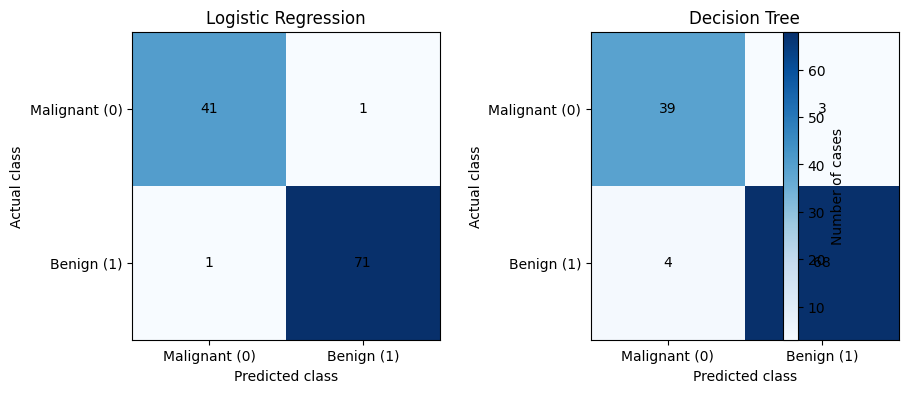

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, (name, predictions) in zip(axes, models.items()):
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    image = axis.imshow(matrix, cmap='Blues')
    axis.set_title(name)
    axis.set_xlabel('Predicted class')
    axis.set_ylabel('Actual class')
    axis.set_xticks([0, 1], ['Malignant (0)', 'Benign (1)'])
    axis.set_yticks([0, 1], ['Malignant (0)', 'Benign (1)'])
    for row in range(2):
        for column in range(2):
            axis.text(column, row, matrix[row, column], ha='center', va='center')
fig.colorbar(image, ax=axes, label='Number of cases')
fig.subplots_adjust(wspace=0.45)
plt.show()

## Observations

Compare the `FP` and `FN` columns in the report. Malignant recall is the share of actual malignant cases found, so it is important because it reduces missed cancers (FN). Improving recall can lower precision by creating more false alarms (FP), so both measures must be considered.